In [1]:
import time
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torchvision.models import inception_v3, Inception_V3_Weights
from torch.utils.data import DataLoader
import numpy as np
from scipy import linalg
from matplotlib import pyplot as plt
from tqdm import tqdm
import random
from pathlib import Path
import sys

sys.path.append(str(Path.cwd().parent))

from img_generation.datasets import Config, DatasetType, load_datasets, VAE_TRANSFORM_MONO
from img_generation.models.vae import VAE, VQVAE, NUM_EMBEDDINGS
from img_generation.models.pixel_cnn import PixelCNN

In [2]:
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.mps.is_available()
    else "cpu"
)
print(device)

cpu


In [3]:
RESULTS_DIR = Path("../experiment_results")
RESULTS_DIR.mkdir(exist_ok=True)

config = Config(
    dataset_type=DatasetType.FASHION_MNIST,
    data_dir="../data/fashion_mnist",
    model_type="vae",
    batch_size=128,
    num_workers=0,
)
train_set, val_set, test_set, classes = load_datasets(config, VAE_TRANSFORM_MONO)
NUM_CLASSES = len(classes)

dataloaders = {
    "train": DataLoader(train_set, batch_size=128, shuffle=True,  drop_last=True,  num_workers=0),
    "val":   DataLoader(val_set,   batch_size=128, shuffle=False, drop_last=False, num_workers=0),
    "test":  DataLoader(test_set,  batch_size=128, shuffle=False, drop_last=False, num_workers=0),
}

Loaded train dataset: 54000 images, 10 classes.


In [4]:
def to_rgb(imgs):
    return imgs.expand(-1, 3, -1, -1) if imgs.shape[1] == 1 else imgs


def calculate_frechet_distance(dist1, dist2, eps=1e-6):
    mu1, sigma1 = np.mean(dist1, axis=0), np.cov(dist1, rowvar=False)
    mu2, sigma2 = np.mean(dist2, axis=0), np.cov(dist2, rowvar=False)
    diff = mu1 - mu2
    covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    if not np.isfinite(covmean).all():
        covmean = linalg.sqrtm((sigma1 + eps * np.eye(sigma1.shape[0])).dot(sigma2 + eps * np.eye(sigma2.shape[0])))
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2 * np.trace(covmean)


_inception = None

def get_inception(device):
    global _inception
    if _inception is None:
        m = inception_v3(weights=Inception_V3_Weights.DEFAULT, transform_input=True)
        m.aux_logits = False
        m.AuxLogits = None
        m.fc = nn.Identity()
        m.eval()
        _inception = m.to(device)
    return _inception


@torch.no_grad()
def extract_inception_features(imgs_01, device, batch_size=64):
    resize = T.Resize((299, 299), antialias=True)
    inception = get_inception(device)
    feats = []
    for i in tqdm(range(0, len(imgs_01), batch_size), desc="Inception features", leave=False):
        batch = to_rgb(resize(imgs_01[i : i + batch_size])).to(device)
        feats.append(inception(batch).cpu().float().numpy())
    return np.concatenate(feats, axis=0)


def save_figure(fig, filename):
    fig.savefig(RESULTS_DIR / filename, dpi=150, bbox_inches="tight")

In [5]:
PRETRAINED_DIR = Path("../pretrained_models")

VAE_CFG = dict(input_channels=1, hidden_dim_channels=32, latent_dim=64,
               num_classes=NUM_CLASSES, class_embed_dim=32)
VAE_LATENT_DIM = VAE_CFG["latent_dim"]

VQVAE_CFG      = dict(in_channels=1, hidden_dim=32, num_embeddings=NUM_EMBEDDINGS)
TOKEN_GRID_SIZE = 7

PIXELCNN_CFG        = dict(c_in=1, c_hidden=64, num_classes=256)
PXCNN_TOKENS_CFG    = dict(c_in=1, c_hidden=64, num_classes=NUM_EMBEDDINGS, on_tokens=True)

In [6]:
loaded_models = {}
vqvae = None


def _load_pixelcnn(cfg, paths):
    for path in paths:
        p = Path(path)
        if not p.exists():
            continue
        if p.suffix == ".ckpt":
            return PixelCNN.load_from_checkpoint(str(p))
        m = PixelCNN(**cfg)
        m.load_state_dict(torch.load(p, map_location=device, weights_only=True))
        return m
    return None


try:
    vae = VAE(**VAE_CFG).to(device)
    vae.load_state_dict(torch.load(PRETRAINED_DIR / "vae" / "cvae.pth", map_location=device, weights_only=True))
    vae.eval()
    loaded_models["CVAE"] = vae
except (FileNotFoundError, RuntimeError) as e:
    print(f"CVAE: {e}")

try:
    vqvae = VQVAE(**VQVAE_CFG).to(device)
    vqvae.load_state_dict(torch.load(PRETRAINED_DIR / "vae" / "vq_vae.pth", map_location=device, weights_only=True))
    vqvae.eval()
except (FileNotFoundError, RuntimeError) as e:
    print(f"VQVAE: {e}")

try:
    pcnn = _load_pixelcnn(PIXELCNN_CFG, [
        PRETRAINED_DIR / "pixel_cnn" / "PixelCNN.ckpt",
        PRETRAINED_DIR / "pixel_cnn" / "pixel_cnn.pth",
    ])
    if pcnn is not None:
        loaded_models["PixelCNN"] = pcnn.to(device).eval()
except RuntimeError as e:
    print(f"PixelCNN: {e}")

if vqvae is not None:
    try:
        pcnn_tok = _load_pixelcnn(PXCNN_TOKENS_CFG, [
            PRETRAINED_DIR / "pixel_cnn_on_tokens" / "PixelCNN_tokens.ckpt",
            PRETRAINED_DIR / "pixel_cnn_on_tokens" / "pixel_cnn.pth",
        ])
        if pcnn_tok is not None:
            loaded_models["PixelCNN on Tokens"] = (pcnn_tok.to(device).eval(), vqvae)
    except RuntimeError as e:
        print(f"PixelCNN on Tokens: {e}")

print(f"Loaded: {list(loaded_models.keys())}")

Loaded: ['CVAE', 'PixelCNN', 'PixelCNN on Tokens']


In [7]:
N_GEN    = 512
N_VIS    = 16
GEN_SEED = 0

_rng          = torch.Generator().manual_seed(GEN_SEED)
z_shared      = torch.randn(N_GEN, VAE_LATENT_DIM, generator=_rng)
labels_shared = torch.randint(0, NUM_CLASSES, (N_GEN,), generator=_rng)


@torch.no_grad()
def generate_vae(model, n, device):
    return model.decoder(z_shared[:n].to(device), labels_shared[:n].to(device)).cpu()


@torch.no_grad()
def generate_pixelcnn(model, n, device):
    torch.manual_seed(GEN_SEED)
    samples = model.sample(img_shape=(n, 1, 28, 28), device=device)
    return samples.float() / (model.num_classes - 1)


@torch.no_grad()
def decode_tokens(vqvae, tokens):
    z_q = vqvae.vq_layer.embedding(tokens.long()).permute(0, 3, 1, 2).contiguous()
    return vqvae.normalize(vqvae.decoder(z_q))


@torch.no_grad()
def generate_pixelcnn_on_tokens(pxcnn_t, vqvae, n, device):
    torch.manual_seed(GEN_SEED)
    tokens = pxcnn_t.sample(img_shape=(n, 1, TOKEN_GRID_SIZE, TOKEN_GRID_SIZE), device=device)
    return decode_tokens(vqvae, tokens.to(device)).cpu()


def _run_generate(name, model, n):
    if name == "CVAE":
        return generate_vae(model, n, device)
    elif name == "PixelCNN":
        return generate_pixelcnn(model, n, device)
    elif name == "PixelCNN on Tokens":
        pxcnn_t, vqvae_m = model
        return generate_pixelcnn_on_tokens(pxcnn_t, vqvae_m, n, device)


In [8]:
test_metrics = {}

if "CVAE" in loaded_models:
    m = loaded_models["CVAE"]
    mse_sum, n_total = 0.0, 0
    with torch.no_grad():
        for x, y in tqdm(dataloaders["test"], desc="CVAE", leave=False):
            x, y = x.to(device), y.to(device)
            x_hat, _, _ = m(x, y)
            mse_sum += nn.functional.mse_loss(x_hat, x, reduction="sum").item()
            n_total += x.size(0)
    test_metrics["CVAE"] = (mse_sum / n_total, "MSE / image", "#4C72B0")

if "PixelCNN" in loaded_models:
    m = loaded_models["PixelCNN"]
    bpd_list = []
    with torch.no_grad():
        for x, _ in tqdm(dataloaders["test"], desc="PixelCNN", leave=False):
            bpd, _ = m.calc_likelihood((x * (m.num_classes - 1)).long().to(device))
            bpd_list.append(bpd.item())
    test_metrics["PixelCNN"] = (float(np.mean(bpd_list)), "pixel space", "#DD8452")

if "PixelCNN on Tokens" in loaded_models:
    pxcnn_t, vqvae_m = loaded_models["PixelCNN on Tokens"]
    bpd_list = []
    with torch.no_grad():
        for x, _ in tqdm(dataloaders["test"], desc="PixelCNN on Tokens", leave=False):
            x = x.to(device)
            _, _, enc_idx = vqvae_m.encode(x)
            tokens = enc_idx.reshape(x.size(0), TOKEN_GRID_SIZE, TOKEN_GRID_SIZE)
            bpd, _ = pxcnn_t.calc_likelihood(tokens)
            bpd_list.append(bpd.item())
    test_metrics["PixelCNN on Tokens"] = (float(np.mean(bpd_list)), "token space", "#55A868")

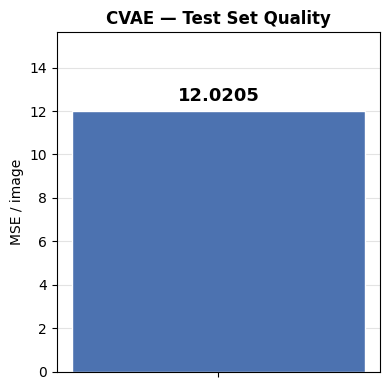

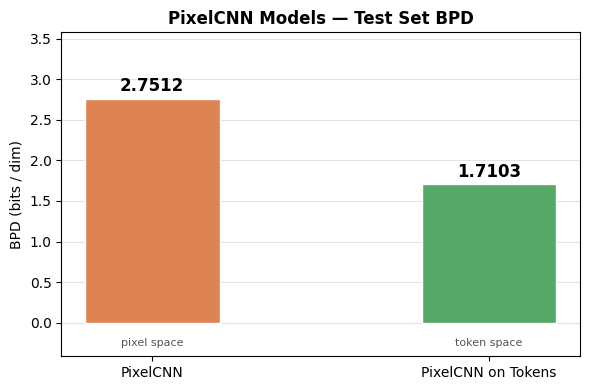

In [9]:
if "CVAE" in test_metrics:
    val, ylabel, color = test_metrics["CVAE"]
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.bar(["CVAE"], [val], color=color, width=0.4, edgecolor="white")
    ax.text(0, val * 1.02, f"{val:.4f}", ha="center", va="bottom", fontsize=13, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_title("CVAE — Test Set Quality", fontsize=12, fontweight="bold")
    ax.tick_params(labelbottom=False)
    ax.set_ylim(0, val * 1.3)
    ax.grid(axis="y", alpha=0.35)
    ax.set_axisbelow(True)
    plt.tight_layout()
    save_figure(fig, "quality_cvae.png")
    plt.show()

pcnn_metrics = {k: v for k, v in test_metrics.items() if k != "CVAE"}
if pcnn_metrics:
    names  = list(pcnn_metrics.keys())
    values = [pcnn_metrics[n][0] for n in names]
    colors = [pcnn_metrics[n][2] for n in names]
    ylabels = [pcnn_metrics[n][1] for n in names]

    fig, ax = plt.subplots(figsize=(6, 4))
    bars = ax.bar(names, values, color=colors, width=0.4, edgecolor="white")
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, val * 1.02,
                f"{val:.4f}", ha="center", va="bottom", fontsize=12, fontweight="bold")
    ax.set_ylabel("BPD (bits / dim)")
    ax.set_title("PixelCNN Models — Test Set BPD", fontsize=12, fontweight="bold")
    ax.set_ylim(0, max(values) * 1.3)
    ax.grid(axis="y", alpha=0.35)
    ax.set_axisbelow(True)
    for bar, lbl in zip(bars, ylabels):
        ax.text(bar.get_x() + bar.get_width() / 2, -max(values) * 0.07,
                lbl, ha="center", va="top", fontsize=8, color="#555")
    ax.set_ylim(bottom=-max(values) * 0.15)
    plt.tight_layout()
    save_figure(fig, "quality_pixelcnn.png")
    plt.show()

In [10]:
generated = {}
gen_times  = {}

for name, model in loaded_models.items():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0   = time.perf_counter()
    imgs = _run_generate(name, model, N_GEN)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    gen_times[name] = time.perf_counter() - t0
    generated[name] = imgs.float().clamp(0, 1)

print(f"Generated {N_GEN} images per model:")
for name, t in gen_times.items():
    print(f"  {name}: {t:.2f}s  ({t/N_GEN:.3f}s / image)")


Generated 512 images per model:
  CVAE: 0.02s  (0.000s / image)
  PixelCNN: 1059.16s  (2.069s / image)
  PixelCNN on Tokens: 7.38s  (0.014s / image)


In [11]:
real_list = []
for x, _ in dataloaders["test"]:
    real_list.append(x)
    if sum(t.size(0) for t in real_list) >= N_GEN:
        break
real_imgs = torch.cat(real_list)[:N_GEN].float()
real_features = extract_inception_features(real_imgs, device)

C:\Users\mateu\AppData\Local\Temp\ipykernel_14888\2025313395.py:9: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


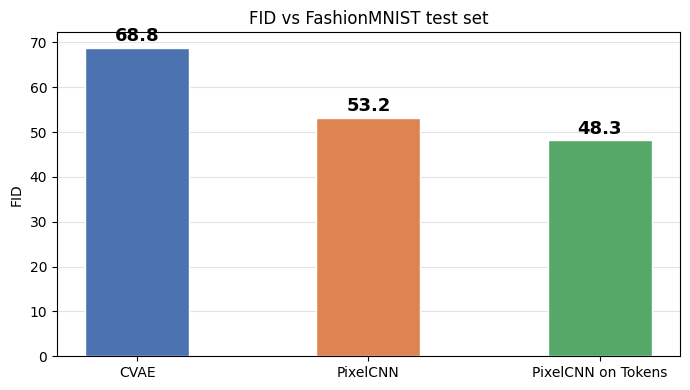

In [12]:
fid_scores = {}

for name, imgs in generated.items():
    fid_scores[name] = calculate_frechet_distance(
        real_features, extract_inception_features(imgs, device)
    )

if fid_scores:
    names  = list(fid_scores.keys())
    fids   = [fid_scores[n] for n in names]
    colors = ["#4C72B0", "#DD8452", "#55A868"][: len(names)]

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(names, fids, color=colors, width=0.45, edgecolor="white")
    for bar, val in zip(bars, fids):
        ax.text(bar.get_x() + bar.get_width() / 2, val * 1.01,
                f"{val:.1f}", ha="center", va="bottom", fontsize=13, fontweight="bold")
    ax.set_title(f"FID vs FashionMNIST test set", fontsize=12)
    ax.set_ylabel("FID")
    ax.grid(axis="y", alpha=0.35)
    ax.set_axisbelow(True)
    plt.tight_layout()
    save_figure(fig, "fid_comparison.png")
    plt.show()


| Model                | Quality metric          | FID    | Gen time    | Per image   |
|----------------------|-------------------------|--------|-------------|-------------|
| CVAE                 | 12.0205 (MSE / image)   | 68.8   | 0.02 s      | 0.000 s     |
| PixelCNN             | 2.7512 (pixel space)    | 53.2   | 1059.16 s   | 2.069 s     |
| PixelCNN on Tokens   | 1.7103 (token space)    | 48.3   | 7.38 s      | 0.014 s     |


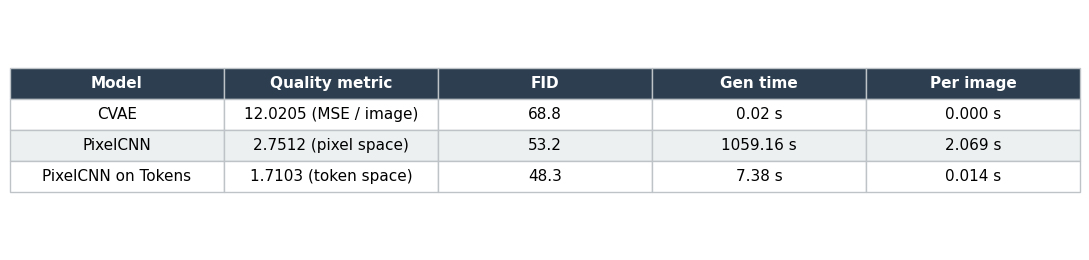

In [13]:
all_names = list(loaded_models.keys())

quality_col = []
for name in all_names:
    if name in test_metrics:
        val, label, _ = test_metrics[name]
        quality_col.append(f"{val:.4f} ({label})")
    else:
        quality_col.append("—")

fid_col      = [f"{fid_scores.get(n, float('nan')):.1f}" for n in all_names]
time_total   = [f"{gen_times.get(n, 0):.2f} s" for n in all_names]
time_per_img = [f"{gen_times.get(n, 0) / N_GEN:.3f} s" for n in all_names]

headers = ["Model", "Quality metric", "FID", "Gen time", "Per image"]
rows    = list(zip(all_names, quality_col, fid_col, time_total, time_per_img))

col_widths = [max(len(headers[i]), max(len(str(r[i])) for r in rows)) + 2 for i in range(len(headers))]

def fmt_row(row):
    return "| " + " | ".join(str(v).ljust(col_widths[i]) for i, v in enumerate(row)) + " |"

sep = "|" + "|".join("-" * (w + 2) for w in col_widths) + "|"
print(fmt_row(headers))
print(sep)
for row in rows:
    print(fmt_row(row))

with open(RESULTS_DIR / "results.csv", "w") as f:
    f.write(",".join(headers) + "\n")
    for row in rows:
        f.write(",".join(str(v) for v in row) + "\n")

fig, ax = plt.subplots(figsize=(11, 0.6 * (len(rows) + 1.5)))
ax.axis("off")
tbl = ax.table(
    cellText=rows,
    colLabels=headers,
    loc="center",
    cellLoc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 1.6)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor("#2c3e50")
        cell.set_text_props(color="white", fontweight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#ecf0f1")
    cell.set_edgecolor("#bdc3c7")
plt.tight_layout()
save_figure(fig, "results_table.png")
plt.show()


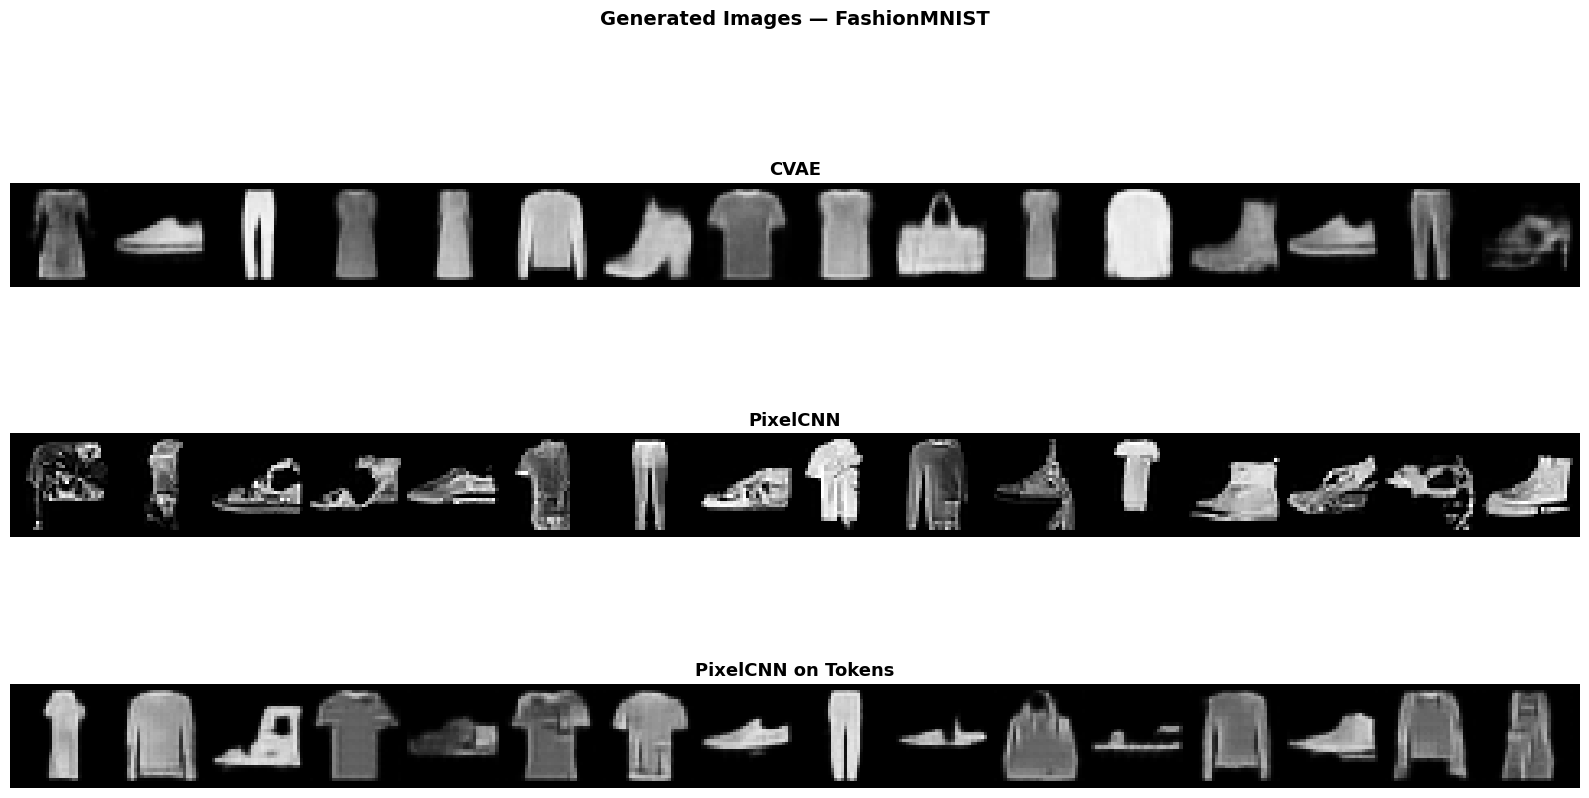

In [14]:
n_rows = len(generated)
fig, axes = plt.subplots(n_rows, 1, figsize=(16, 3 * n_rows))
if n_rows == 1:
    axes = [axes]

for ax, (name, imgs) in zip(axes, generated.items()):
    grid = torchvision.utils.make_grid(imgs[:N_VIS], nrow=N_VIS, padding=2)
    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_title(name, fontsize=13, fontweight="bold", pad=6)
    ax.axis("off")

plt.suptitle(f"Generated Images — FashionMNIST",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
save_figure(fig, "generated_samples.png")
plt.show()